# Predicting Customer Churn for a Telecom Provider

**Applied data science portfolio option A**

**project:** a telecom company loses some of its customers every month. they cancel, switch to a competitor or just stop paying. We want to spot the customers who are likely to leave before they do so the retention team can step in.

**Dataset:** 7,043 customers and 21 columns from the IBM Telco Customer Churn dataset on Kaggle. One row is one customer. The column we want to predict is `Churn` which says whether the customer left in the last month.

### The route through the project

| Phase | Question we answer |
|---|---|
| 1. Define the problem | who uses the prediction and what counts as a good result? |
| 2. Load the data | does the file load correctly? |
| 3. Audit and clean | what's missing or broken, and how do we fix it? |
| 4. Explore | which customers churn more? |
| 5. Feature engineering | what new inputs could help the model? |
| 6. Split the data | how do we test the model fairly? |
| 7. Prepare the inputs | how do we turn text into numbers? |
| 8. Train and compare models | which model works best on validation data? |
| 9. Choose a cutoff | where do we draw the line between churn and no churn? |
| 10. Final test | how does the chosen model do on data it has never seen? |
| 11. What drives churn | which inputs matter most, and what can't we conclude? |
| 12. Fairness check | does the model treat groups of customers differently? |
| 13. Business value | who should the company actually contact? |
| 14. Save and reuse the model | can someone else load it and get the same answers? |


## 1. The problem

The retention team wants a list of customers who are likely to leave, so they can reach out with an offer before it happens. Our model gives each customer a churn probability, and a cutoff turns that into a yes or no.

The target is `Churn`, 1 if the customer left and 0 if they stayed. Churn is the positive class, so precision and recall here are always about churners. `customerID` is just an ID so we don't use it as an input.

Missing a churner is usually worse than a false alarm. A missed churner means lost revenue, while a false alarm just means one offer went to someone who would have stayed anyway. So recall matters a lot, but precision can't be too low either or the company wastes money on offers. We use F1 to compare models since it balances both.

Every model also has to beat a basic baseline that predicts "stays" for everyone.

## 2. Loading the data

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

# chart settings
pd.set_option('display.max_columns', 30)
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

In [2]:
data_path = Path('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# in colab, upload the csv if it isn't there yet
if not data_path.exists():
    from google.colab import files
    uploaded = files.upload()
    data_path = Path(list(uploaded.keys())[0])

df = pd.read_csv(data_path)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Checking and cleaning the data

In [3]:
# data types, missing values and unique values per column
audit = pd.DataFrame({
    'data_type': df.dtypes.astype(str),
    'missing_count': df.isna().sum(),
    'unique_values': df.nunique(),
})
audit

,data_type,missing_count,unique_values
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


Nothing shows as missing, but `TotalCharges` is stored as text when it should be a number, so some rows probably have blanks in them. `SeniorCitizen` uses 0/1 while the other yes/no columns use Yes and No.

In [4]:
# rows where TotalCharges can't be turned into a number
total_as_number = pd.to_numeric(df['TotalCharges'], errors='coerce')
blank_rows = df[total_as_number.isna()]

print('rows with blank TotalCharges:', len(blank_rows))
blank_rows[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

rows with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All 11 of these customers have a tenure of 0. they just joined and haven't been billed yet, so their total charges should actually be 0. We fill them with 0 instead of dropping them.

In [5]:
print('duplicate rows:', df.duplicated().sum())
print('repeated customer ids:', df['customerID'].duplicated().sum())

# checking the ranges for anything unusual
df[['tenure', 'MonthlyCharges']].describe().round(2)

duplicate rows: 0
repeated customer ids: 0


,tenure,MonthlyCharges
count,7043.00,7043.00
mean,32.37,64.76
std,24.56,30.09
min,0.00,18.25
25%,9.00,35.50
50%,29.00,70.35
75%,55.00,89.85
max,72.00,118.75


No duplicates, and the ranges look normal. Tenure goes from 0 to 72 months and monthly charges from about \$18 to \$119, so there aren't any outliers to remove.

Cleaning steps:
1. Convert `TotalCharges` to a number and fill the 11 new customers with 0
2. Change `SeniorCitizen` to Yes/No to match the other columns
3. Merge "No internet service" and "No phone service" into "No". A customer without internet can't have online security anyway, and the `InternetService` column already tells us they have no internet
4. Turn `Churn` into 1 and 0

These are fixed rules and nothing is learned from the data here, so it's fine to do this before splitting.

In [6]:
df = df.copy()

# blank totals are new customers, so they become 0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# "no internet service" and "no phone service" just mean no
service_columns = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                   'TechSupport', 'StreamingTV', 'StreamingMovies']
for column in service_columns:
    df[column] = df[column].replace({'No internet service': 'No', 'No phone service': 'No'})

# 1 = churned, 0 = stayed
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

print('missing values left:', df.isna().sum().sum())

missing values left: 0


## 4. Exploring the data

### Churn rate

churn rate: 26.5 %


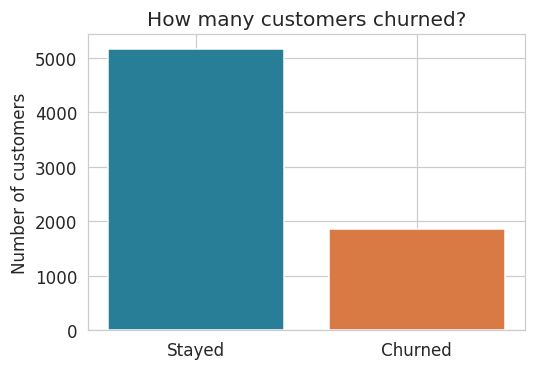

In [7]:
print('churn rate:', round(df['Churn'].mean() * 100, 1), '%')

counts = df['Churn'].map({0: 'Stayed', 1: 'Churned'}).value_counts()
plt.figure(figsize=(5, 3.5))
plt.bar(counts.index, counts.values, color=['#287E96', '#D97A45'])
plt.ylabel('Number of customers')
plt.title('How many customers churned?')
plt.tight_layout()
plt.show()

26.5% of customers churned, so the classes are imbalanced, about 3 stayers for every churner. A model that just says "stays" for everyone would be around 73% accurate without catching a single churner, which is why accuracy alone isn't enough for this problem.

In [8]:
# churn rate in % for each group in a column
def churn_rate_by(column):
    return (df.groupby(column, observed=True)['Churn'].mean() * 100).round(1)

### Contract type

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


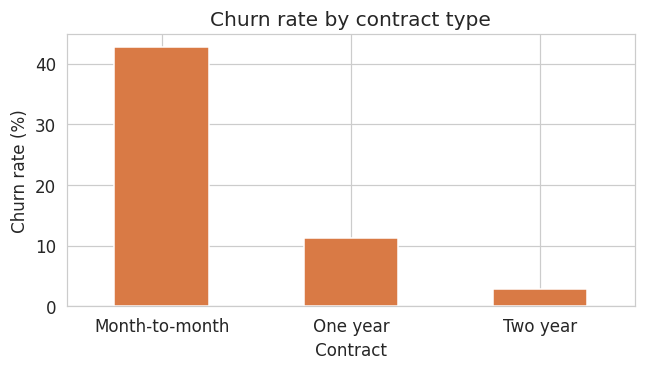

In [9]:
rates = churn_rate_by('Contract')
print(rates)

rates.plot(kind='bar', color='#D97A45', figsize=(6, 3.5))
plt.ylabel('Churn rate (%)')
plt.title('Churn rate by contract type')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

This is the strongest pattern in the data. Month-to-month customers churn at about 43%, one-year at 11% and two-year at under 3%.

That doesn't mean the contract itself is what keeps people. Customers who aren't sure about the service are more likely to pick month-to-month in the first place, so it's probably a bit of both.

### Tenure

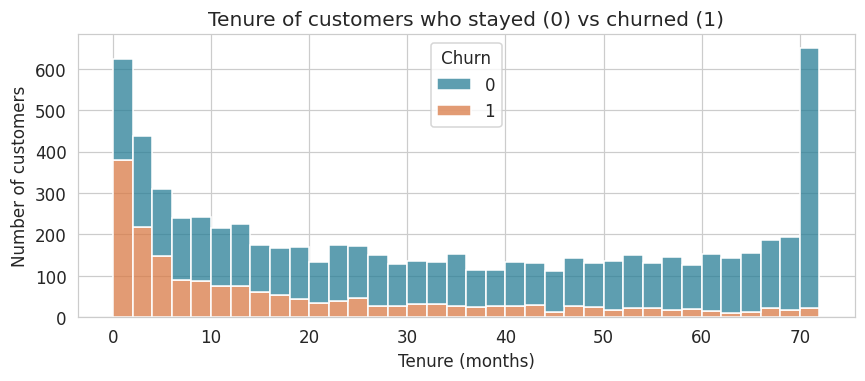

In [10]:
plt.figure(figsize=(8, 3.6))
sns.histplot(data=df, x='tenure', hue='Churn', bins=36, multiple='stack',
             palette=['#287E96', '#D97A45'])
plt.xlabel('Tenure (months)')
plt.ylabel('Number of customers')
plt.title('Tenure of customers who stayed (0) vs churned (1)')
plt.tight_layout()
plt.show()

Most churn happens in the first few months. after a couple of years customers rarely leave.

### Monthly charges

Churn
0    61.27
1    74.44
Name: MonthlyCharges, dtype: float64


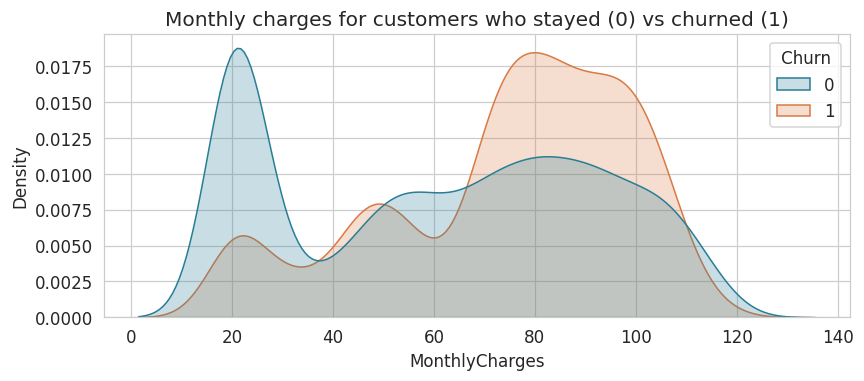

In [11]:
print(df.groupby('Churn')['MonthlyCharges'].mean().round(2))

# common_norm=False so both groups are scaled on their own
plt.figure(figsize=(8, 3.6))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False,
            palette=['#287E96', '#D97A45'])
plt.title('Monthly charges for customers who stayed (0) vs churned (1)')
plt.tight_layout()
plt.show()

Churners pay more on average, around \$74 vs \$61. There's a big group of churners between \$70 and \$105, which matches the fiber optic price range.

### Internet service and payment method

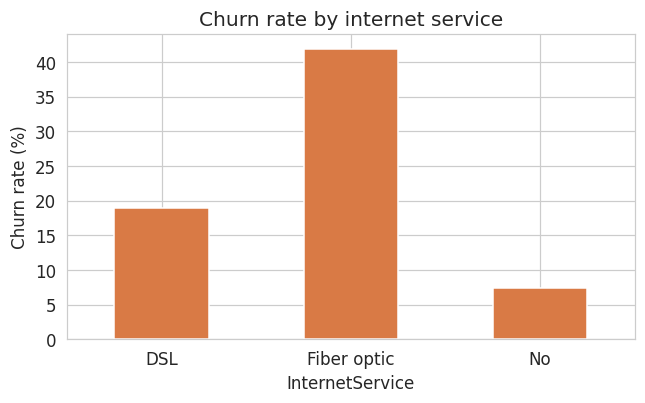

In [12]:
plt.figure(figsize=(6, 3.8))
churn_rate_by('InternetService').plot(kind='bar', color='#D97A45')
plt.title('Churn rate by internet service')
plt.ylabel('Churn rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

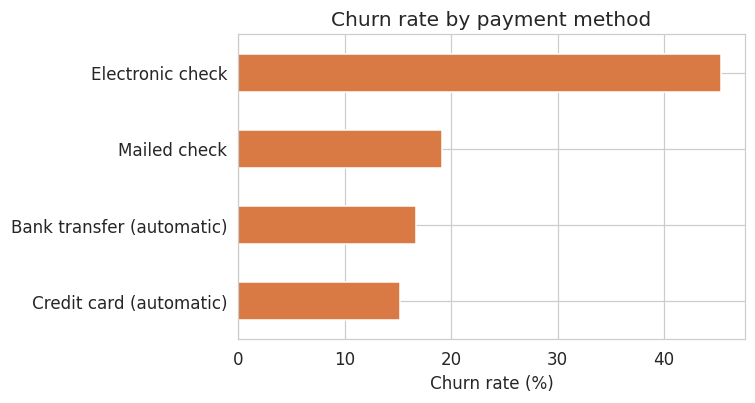

In [13]:
plt.figure(figsize=(7, 3.8))
churn_rate_by('PaymentMethod').sort_values().plot(kind='barh', color='#D97A45')
plt.title('Churn rate by payment method')
plt.xlabel('Churn rate (%)')
plt.ylabel('')
plt.tight_layout()
plt.show()

Fiber optic customers churn at around 42%, which is odd for the premium product. could be price or could be service quality, the data doesn't say which.

Electronic check users churn at about 45%, way more than people on automatic payments. Paying manually every month probably makes people think about cancelling more often.

### Add-on services

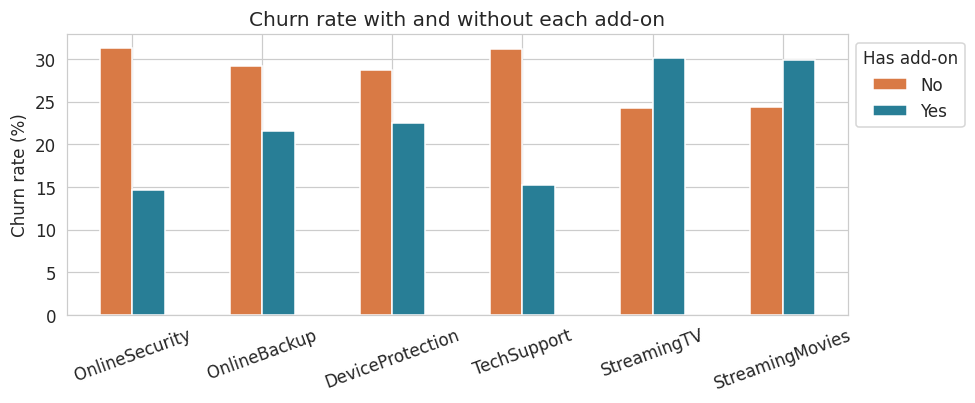

In [14]:
addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
          'StreamingTV', 'StreamingMovies']

# churn rate with and without each add-on
addon_rates = pd.DataFrame({column: churn_rate_by(column) for column in addons}).T
addon_rates.plot(kind='bar', color=['#D97A45', '#287E96'], figsize=(9, 3.8))
plt.ylabel('Churn rate (%)')
plt.title('Churn rate with and without each add-on')
plt.xticks(rotation=20)
plt.legend(title='Has add-on', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Without online security or tech support churn is around 31%, with them it's about 15%. Streaming add-ons don't really help, streaming customers actually churn slightly more.

### Customer demographics

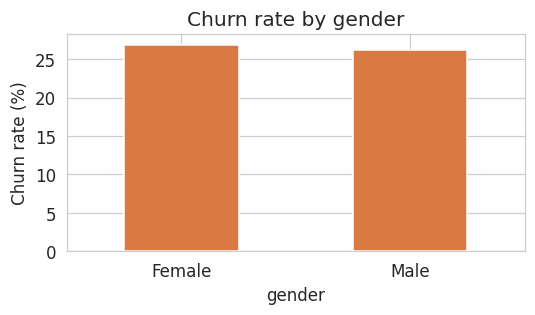

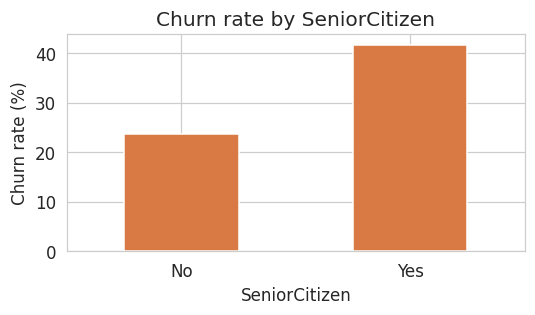

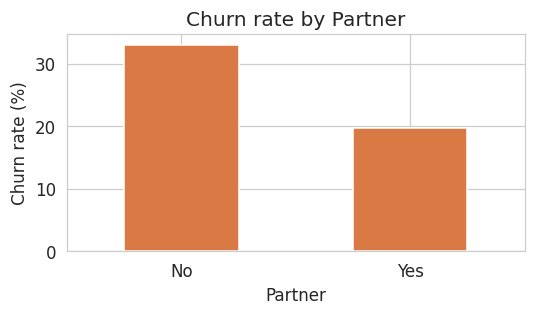

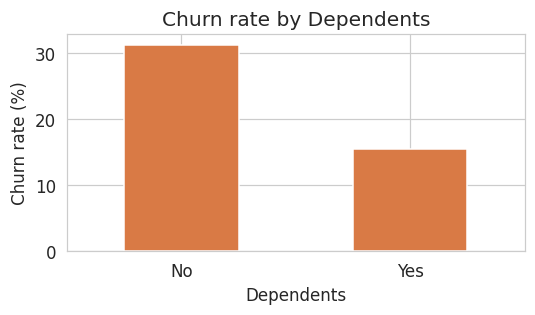

In [15]:
# one chart for each column
for column in ['gender', 'SeniorCitizen', 'Partner', 'Dependents']:
    plt.figure(figsize=(5, 3))
    churn_rate_by(column).plot(kind='bar', color='#D97A45')
    plt.title(f'Churn rate by {column}')
    plt.ylabel('Churn rate (%)')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

Gender makes basically no difference. Seniors churn a lot more, 42% vs 24%, and customers without a partner or dependents churn more too.

### Correlation

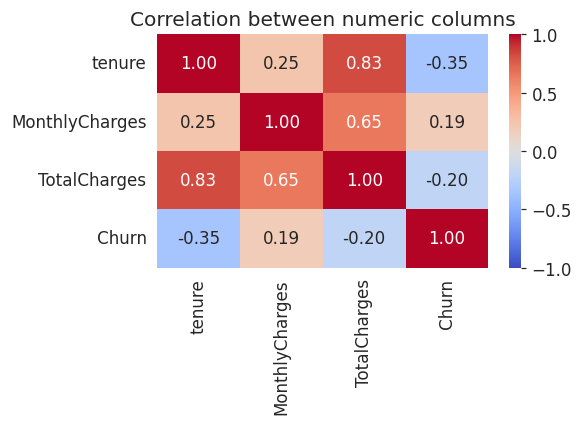

In [16]:
plt.figure(figsize=(5.5, 4))
sns.heatmap(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between numeric columns')
plt.tight_layout()
plt.show()

`TotalCharges` and `tenure` are correlated at 0.83, which makes sense since total charges builds up the longer you stay. tenure has the strongest negative link with churn.

## 5. Feature engineering

We added three features based on what we saw above:

| Feature | What it is | Why |
|---|---|---|
| `num_addons` | number of add-on services, 0 to 6 | more services seemed to go with lower churn |
| `tenure_group` | tenure grouped into 0-1yr, 1-2yr, 2-4yr, 4-6yr | churn drops a lot after the first year |
| `auto_pay` | Yes if paying by automatic bank transfer or card | manual payers churn about twice as much |

We put all the steps into one function so the same thing can be applied to new customers later.

In [17]:
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'num_addons']

categorical_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
                        'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                        'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                        'Contract', 'PaperlessBilling', 'PaymentMethod',
                        'tenure_group', 'auto_pay']

feature_columns = numeric_features + categorical_features


def prepare_features(customers):
    result = customers.copy()

    # count how many add-ons each customer has
    result['num_addons'] = (result[addons] == 'Yes').sum(axis=1)

    # group tenure into years
    result['tenure_group'] = pd.cut(result['tenure'], bins=[-1, 12, 24, 48, 72],
                                    labels=['0-1yr', '1-2yr', '2-4yr', '4-6yr']).astype(str)

    # yes if they pay by automatic bank transfer or card
    is_automatic = result['PaymentMethod'].str.contains('automatic')
    result['auto_pay'] = np.where(is_automatic, 'Yes', 'No')

    return result[feature_columns]

Checking that the new features actually relate to churn:

In [18]:
check = prepare_features(df)
check['Churn'] = df['Churn']

# churn rate for each value of the new features
for column in ['num_addons', 'tenure_group', 'auto_pay']:
    print((check.groupby(column)['Churn'].mean() * 100).round(1), '\n')

num_addons
0    21.4
1    45.8
2    35.8
3    27.4
4    22.3
5    12.4
6     5.3
Name: Churn, dtype: float64 

tenure_group
0-1yr    47.4
1-2yr    28.7
2-4yr    20.4
4-6yr     9.5
Name: Churn, dtype: float64 

auto_pay
No     34.7
Yes    16.0
Name: Churn, dtype: float64 



All three show a clear pattern. churn goes from 47% in the first year down to under 10% after four years, and auto-pay customers churn at 16% vs 35%.

For add-ons, churn falls from 46% with one add-on to 5% with all six. Zero add-ons is lower at 21%, but that's because most of those customers don't have internet at all and they rarely churn. The model still sees `InternetService` so it can tell them apart.

## 6. Train, validation and test split

We split the data 60/20/20. The training set is used to fit and tune the models, the validation set to compare them and choose a cutoff, and the test set is only used once at the very end on the final model.

`stratify` keeps the churn rate the same in all three sets.

In [19]:
X = prepare_features(df)
y = df['Churn']

# take out 20% for the test set first
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

# then 25% of what's left for validation, which is 20% of the full data
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

pd.DataFrame({
    'set': ['Training', 'Validation', 'Test'],
    'customers': [len(X_train), len(X_val), len(X_test)],
    'churn rate %': [round(y_train.mean() * 100, 1), round(y_val.mean() * 100, 1),
                     round(y_test.mean() * 100, 1)],
})

,set,customers,churn rate %
0,Training,4225,26.5
1,Validation,1409,26.5
2,Test,1409,26.5


4,225 / 1,409 / 1,409 customers, with a 26.5% churn rate in each.

## 7. Preparing the inputs

Numeric columns get scaled with `StandardScaler` and categorical columns get one-hot encoded. The scaling mainly helps logistic regression. The tree models don't need it but it doesn't hurt them, so we use the same steps for every model.

Everything goes in a pipeline so the scaler only learns from the training data, and the same steps get applied to the validation set, test set and new customers.

In [20]:
# scale the numeric columns, one-hot encode the categorical ones
preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_features),
    ('categories', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False),
     categorical_features),
], verbose_feature_names_out=False)


# preprocessing + model in one pipeline
def make_model(classifier):
    return Pipeline([
        ('prepare', clone(preprocessor)),
        ('model', classifier),
    ])

## 8. Training and comparing models

We score every model the same way on the validation set. Training F1 is there too so we can spot overfitting.

In [21]:
candidates = {}
validation_results = []


# same metrics for every model
def evaluate_on_validation(name, fitted_model):
    val_pred = fitted_model.predict(X_val)
    train_pred = fitted_model.predict(X_train)
    return {
        'Model': name,
        'Training F1': f1_score(y_train, train_pred),
        'Accuracy': accuracy_score(y_val, val_pred),
        'Precision': precision_score(y_val, val_pred, zero_division=0),
        'Recall': recall_score(y_val, val_pred),
        'F1-score': f1_score(y_val, val_pred),
    }

### Baseline

In [22]:
# always predicts the most common class, which is "stayed"
baseline = make_model(DummyClassifier(strategy='most_frequent'))
baseline.fit(X_train, y_train)

candidates['Baseline'] = baseline
validation_results.append(evaluate_on_validation('Baseline', baseline))
pd.DataFrame(validation_results).round(3)

,Model,Training F1,Accuracy,Precision,Recall,F1-score
0,Baseline,0.0,0.735,0.0,0.0,0.0


73% accuracy but 0 recall, it doesn't catch any churners.

### Logistic regression

We train it once normally and once with `class_weight='balanced'`, which makes the model pay more attention to the smaller churn class.

In [23]:
# without class weights
log_reg_plain = make_model(LogisticRegression(max_iter=1000))
log_reg_plain.fit(X_train, y_train)
candidates['Logistic regression, unbalanced'] = log_reg_plain
validation_results.append(evaluate_on_validation('Logistic regression, unbalanced', log_reg_plain))

# with balanced class weights
log_reg = make_model(LogisticRegression(max_iter=1000, class_weight='balanced'))
log_reg.fit(X_train, y_train)
candidates['Logistic regression'] = log_reg
validation_results.append(evaluate_on_validation('Logistic regression', log_reg))

pd.DataFrame(validation_results).round(3)

,Model,Training F1,Accuracy,Precision,Recall,F1-score
0,Baseline,0.000,0.735,0.000,0.000,0.000
1,"Logistic regression, unbalanced",0.605,0.802,0.661,0.521,0.583
2,Logistic regression,0.637,0.745,0.513,0.786,0.621


Balancing helps a lot. recall goes from about 52% to 79%. Precision drops since more people get flagged, but F1 goes up overall, so all the models from here use balanced class weights.

### Decision tree

`GridSearchCV` tries different depths with 5-fold cross validation on the training set and keeps the one with the best F1.

In [24]:
# try different depths with 5-fold cross validation
tree_search = GridSearchCV(
    make_model(DecisionTreeClassifier(class_weight='balanced', random_state=42)),
    param_grid={'model__max_depth': [3, 4, 5, 6, 8, 10]},
    scoring='f1', cv=5)
tree_search.fit(X_train, y_train)

print('best depth:', tree_search.best_params_['model__max_depth'])
print('cross validated F1:', round(tree_search.best_score_, 3))

tree = tree_search.best_estimator_
candidates['Decision tree'] = tree
validation_results.append(evaluate_on_validation('Decision tree', tree))
pd.DataFrame(validation_results).round(3)

best depth: 3
cross validated F1: 0.624


,Model,Training F1,Accuracy,Precision,Recall,F1-score
0,Baseline,0.000,0.735,0.000,0.000,0.000
1,"Logistic regression, unbalanced",0.605,0.802,0.661,0.521,0.583
2,Logistic regression,0.637,0.745,0.513,0.786,0.621
3,Decision tree,0.626,0.735,0.500,0.775,0.608


### Random forest

Here we tune `max_depth` and `min_samples_leaf`, which control how complex each tree gets.

In [25]:
# 300 trees, tuning depth and leaf size
forest_search = GridSearchCV(
    make_model(RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)),
    param_grid={'model__max_depth': [5, 8, 12],
                'model__min_samples_leaf': [1, 5, 10]},
    scoring='f1', cv=5)
forest_search.fit(X_train, y_train)

print('best settings:', forest_search.best_params_)
print('cross validated F1:', round(forest_search.best_score_, 3))

forest = forest_search.best_estimator_
candidates['Random forest'] = forest
validation_results.append(evaluate_on_validation('Random forest', forest))

best settings: {'model__max_depth': 8, 'model__min_samples_leaf': 1}
cross validated F1: 0.641


### Comparison on the validation set

,Model,Training F1,Accuracy,Precision,Recall,F1-score
0,Baseline,0.000,0.735,0.000,0.000,0.000
1,"Logistic regression, unbalanced",0.605,0.802,0.661,0.521,0.583
2,Logistic regression,0.637,0.745,0.513,0.786,0.621
3,Decision tree,0.626,0.735,0.500,0.775,0.608
4,Random forest,0.707,0.762,0.535,0.770,0.632


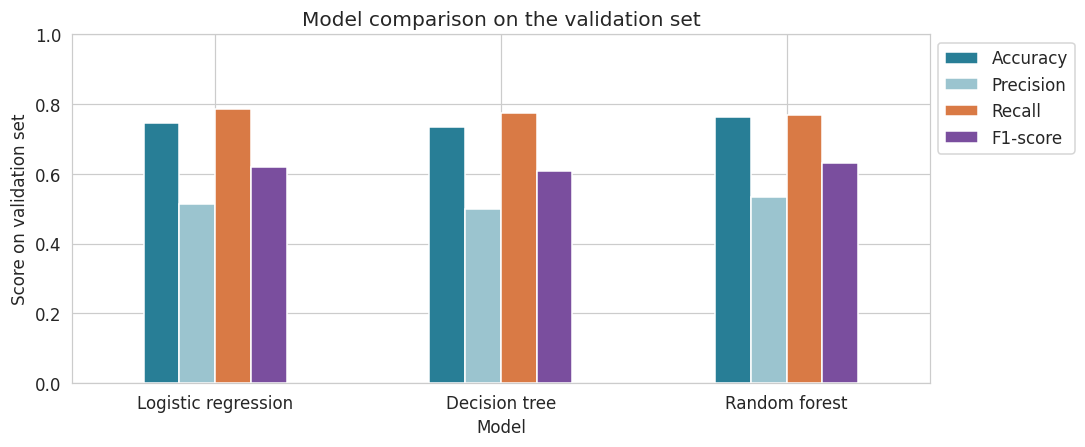

In [26]:
comparison = pd.DataFrame(validation_results).round(3)
display(comparison)

# only plotting the three main models
to_plot = comparison[~comparison['Model'].isin(['Baseline', 'Logistic regression, unbalanced'])]
to_plot.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot(
    kind='bar', figsize=(10, 4.2), color=['#287E96', '#9BC4CF', '#D97A45', '#7A4E9E'])
plt.ylim(0, 1)
plt.ylabel('Score on validation set')
plt.title('Model comparison on the validation set')
plt.xticks(rotation=0)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [27]:
# pick the model with the best validation F1
real_models = comparison[~comparison['Model'].isin(['Baseline', 'Logistic regression, unbalanced'])]
selected_name = real_models.sort_values('F1-score', ascending=False).iloc[0]['Model']
selected_model = candidates[selected_name]
print('selected model:', selected_name)

selected model: Random forest


All three models beat the baseline by a lot and catch around 78% of churners. The scores are close, but the random forest has the best validation F1 at 0.630, so we go with that. Logistic regression is right behind at 0.621 and would be a fine choice too if it needed to be easier to explain.

The forest's training F1 is 0.73 vs 0.63 on validation, so it overfits a little, but it still does best on data it hasn't seen.

## 9. Choosing a cutoff

The default cutoff is 0.5. A lower cutoff catches more churners but gives more false alarms, and a higher one does the opposite. We try a range of cutoffs on the validation set and pick the one with the best F1.

In [28]:
# churn probabilities for the validation set
val_prob = selected_model.predict_proba(X_val)[:, 1]

# test cutoffs from 0.30 to 0.70
cutoff_rows = []
for cutoff in np.arange(0.30, 0.71, 0.05):
    pred = (val_prob >= cutoff).astype(int)
    cutoff_rows.append({
        'Cutoff': round(cutoff, 2),
        'Customers flagged': int(pred.sum()),
        'Precision': precision_score(y_val, pred),
        'Recall': recall_score(y_val, pred),
        'F1-score': f1_score(y_val, pred),
    })

cutoff_table = pd.DataFrame(cutoff_rows).round(3)
display(cutoff_table)

best_cutoff = float(cutoff_table.sort_values('F1-score', ascending=False).iloc[0]['Cutoff'])
print('best cutoff:', best_cutoff)

,Cutoff,Customers flagged,Precision,Recall,F1-score
0,0.30,761,0.434,0.882,0.581
1,0.35,700,0.463,0.866,0.603
2,0.40,645,0.487,0.840,0.616
3,0.45,584,0.507,0.791,0.618
4,0.50,538,0.535,0.770,0.632
5,0.55,480,0.569,0.730,0.639
6,0.60,418,0.600,0.671,0.634
7,0.65,341,0.657,0.599,0.627
8,0.70,275,0.684,0.503,0.579


best cutoff: 0.55


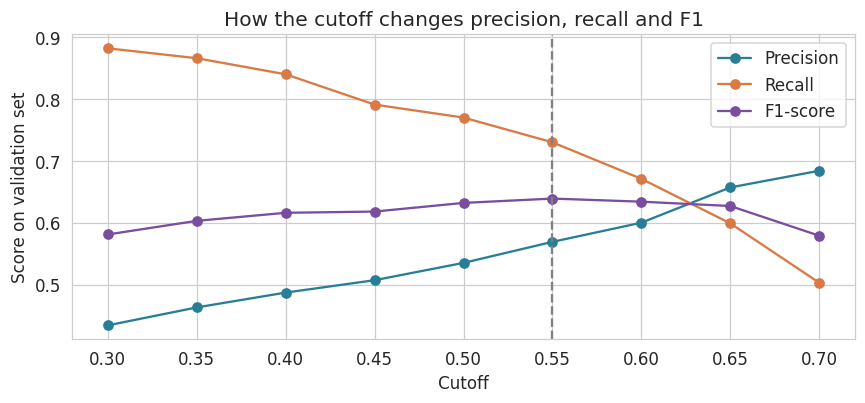

In [29]:
plt.figure(figsize=(8, 3.8))
plt.plot(cutoff_table['Cutoff'], cutoff_table['Precision'], marker='o', label='Precision', color='#287E96')
plt.plot(cutoff_table['Cutoff'], cutoff_table['Recall'], marker='o', label='Recall', color='#D97A45')
plt.plot(cutoff_table['Cutoff'], cutoff_table['F1-score'], marker='o', label='F1-score', color='#7A4E9E')
# dashed line marks the chosen cutoff
plt.axvline(best_cutoff, linestyle='--', color='grey')
plt.xlabel('Cutoff')
plt.ylabel('Score on validation set')
plt.title('How the cutoff changes precision, recall and F1')
plt.legend()
plt.tight_layout()
plt.show()

F1 is pretty flat between 0.50 and 0.60. The best is 0.55, so we use that.

If the company cared more about catching every churner, something like 0.40 would catch about 85% of them, but with a lot more false alarms. that's more of a business call.

## 10. Final test

Now that the model and cutoff are chosen, we refit the model on the training and validation data combined and score it on the test set.

In [30]:
# combine training and validation for the final fit
X_development = pd.concat([X_train, X_val])
y_development = pd.concat([y_train, y_val])

# clone copies the settings but starts the training fresh
final_model = clone(selected_model)
final_model.fit(X_development, y_development)

final_baseline = clone(baseline)
final_baseline.fit(X_development, y_development)

Pipeline(steps=[('prepare',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges',
                                                   'num_addons']),
                                                 ('categories',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'tenure_group',
                                                   'auto_pay'])],
                                   verbose_feature_names_out=False)),
                ('model', DummyClassifier(strategy='most_frequent'))])

In [31]:
# predictions on the test set using our cutoff
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_cutoff).astype(int)
baseline_test_pred = final_baseline.predict(X_test)

test_rows = []
for name, pred in [('Baseline', baseline_test_pred), (selected_name, test_pred)]:
    test_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred),
        'F1-score': f1_score(y_test, pred),
    })

pd.DataFrame(test_rows).round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Baseline,0.735,0.000,0.000,0.00
1,Random forest,0.773,0.555,0.727,0.63


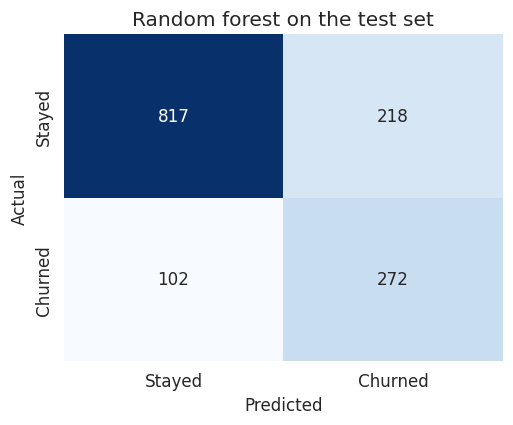

In [32]:
matrix = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(4.8, 4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'{selected_name} on the test set')
plt.tight_layout()
plt.show()

On the test set the random forest gets an F1 of 0.63, about the same as on validation, so it holds up on new data. It caught 269 of the 374 churners, which is 72% recall, while the baseline caught none.

The tradeoff is 217 false alarms, so precision is around 55%. accuracy is 77%, only a few points above the baseline, which again shows accuracy isn't the right measure here.

## 11. What drives churn

### Permutation importance

Shuffle one column at a time and see how much F1 drops. A big drop means the model relies on that column.

,Feature,Drop in F1 when shuffled
17,Contract,0.155
10,InternetService,0.117
0,tenure,0.037
20,tenure_group,0.023
2,TotalCharges,0.014
1,MonthlyCharges,0.013
3,num_addons,0.005
7,Dependents,0.004
14,TechSupport,0.003
18,PaperlessBilling,0.002


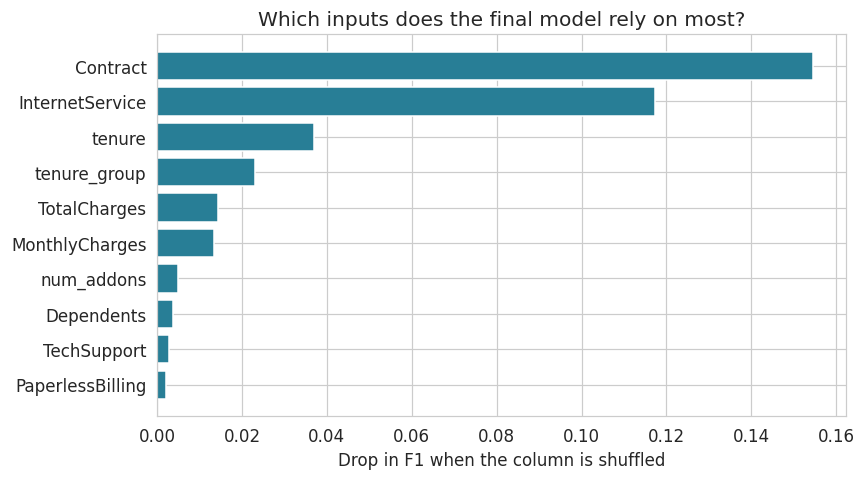

In [33]:
# F1 using our cutoff instead of the default 0.5
def f1_at_cutoff(model, X_part, y_part):
    prob = model.predict_proba(X_part)[:, 1]
    return f1_score(y_part, (prob >= best_cutoff).astype(int))

# shuffle each column 5 times and see how much F1 drops
permutation = permutation_importance(final_model, X_test, y_test, scoring=f1_at_cutoff,
                                     n_repeats=5, random_state=42)

importance = pd.DataFrame({
    'Feature': feature_columns,
    'Drop in F1 when shuffled': permutation.importances_mean,
}).sort_values('Drop in F1 when shuffled', ascending=False)

display(importance.head(10).round(3))

top = importance.head(10).iloc[::-1]
plt.figure(figsize=(8, 4.5))
plt.barh(top['Feature'], top['Drop in F1 when shuffled'], color='#287E96')
plt.xlabel('Drop in F1 when the column is shuffled')
plt.title('Which inputs does the final model rely on most?')
plt.tight_layout()
plt.show()

Contract matters the most, then internet service and tenure. A lot of the other columns barely move the score, but that's partly because many of them overlap, like `tenure`, `tenure_group` and `TotalCharges`. When one gets shuffled the model can still use the others.

### Logistic regression coefficients

These show the direction. positive means higher churn risk, negative means lower.

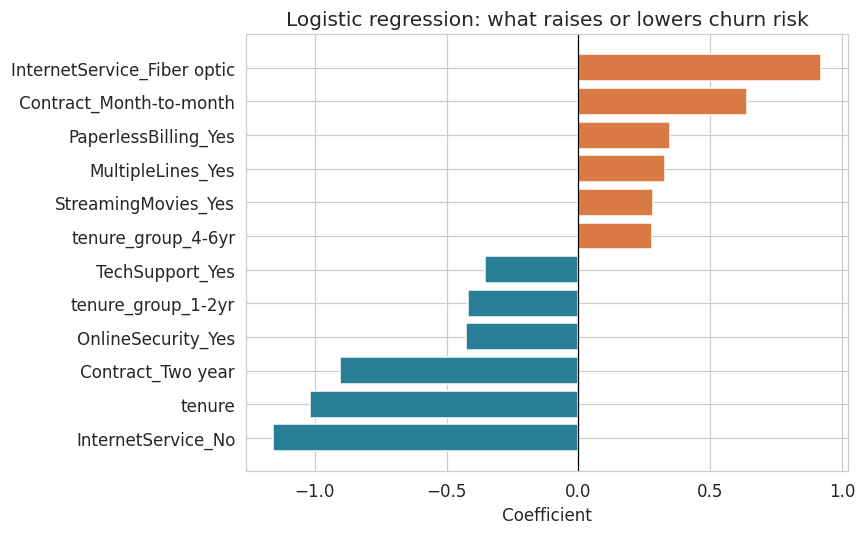

In [34]:
# refit logistic regression on the same data as the final model
lr_final = clone(log_reg).fit(X_development, y_development)

coef_names = lr_final.named_steps['prepare'].get_feature_names_out()
coefs = pd.Series(lr_final.named_steps['model'].coef_[0], index=coef_names).sort_values()

# 6 most negative and 6 most positive
top_coefs = pd.concat([coefs.head(6), coefs.tail(6)])
colors = ['#287E96' if value < 0 else '#D97A45' for value in top_coefs]

plt.figure(figsize=(8, 5))
plt.barh(top_coefs.index, top_coefs.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient')
plt.title('Logistic regression: what raises or lowers churn risk')
plt.tight_layout()
plt.show()

Fiber optic and month-to-month contracts push churn risk up the most. two-year contracts, longer tenure, online security and tech support push it down. Customers with no internet rarely leave.

`tenure_group_4-6yr` coming out positive looks wrong, but it's because it overlaps with `tenure`, so the model splits the effect between them. Overall the tenure effect is still clearly negative.

### Correlation vs causation

All of this is association, not cause. Month-to-month customers churn more, but that doesn't mean forcing everyone onto long contracts would fix it, since unsure customers tend to pick short contracts anyway. Same with tech support, it might keep people happy, or the people who buy it might already be more committed. For fiber optic it could be price, reliability or competitors and we can't tell which.

The only real way to know would be an experiment, like giving free tech support to a random group of new customers and comparing their churn with a group that didn't get it.

The data also doesn't include complaints, support calls, competitor prices, network quality or reasons for leaving, and it's a single snapshot so we can't see changes over time.

## 12. Fairness check

We look at whether the model treats gender groups and senior citizens differently. The false alarm rate is the share of customers who stayed but still got flagged.

In [35]:
fairness_data = X_test[['gender', 'SeniorCitizen']].copy()
fairness_data['actual'] = y_test.values
fairness_data['predicted'] = test_pred


def group_report(column):
    rows = []
    for group, part in fairness_data.groupby(column):
        # customers in this group who actually stayed
        stayed = part[part['actual'] == 0]
        rows.append({
            column: group,
            'Customers': len(part),
            'Actual churn %': round(part['actual'].mean() * 100, 1),
            '% flagged': round(part['predicted'].mean() * 100, 1),
            'Recall': round(recall_score(part['actual'], part['predicted']), 3),
            'Precision': round(precision_score(part['actual'], part['predicted']), 3),
            'False alarm rate': round(stayed['predicted'].mean(), 3),
        })
    return pd.DataFrame(rows)


display(group_report('gender'))
display(group_report('SeniorCitizen'))

,gender,Customers,Actual churn %,% flagged,Recall,Precision,False alarm rate
0,Female,687,28.1,34.5,0.710,0.578,0.202
1,Male,722,25.1,35.0,0.746,0.534,0.218


,SeniorCitizen,Customers,Actual churn %,% flagged,Recall,Precision,False alarm rate
0,No,1187,23.3,30.0,0.681,0.528,0.184
1,Yes,222,44.1,60.4,0.857,0.627,0.403


Men and women are treated about the same, both flagged around 34% of the time with similar recall and false alarm rates.

Seniors are different. 60% of seniors get flagged compared to 30% of non-seniors. Part of that is fair because seniors do churn more, 44% vs 23%. But the false alarm rate is 0.40 for seniors vs 0.18 for everyone else, so a senior who was going to stay is about twice as likely to be wrongly flagged.

If being flagged just means getting a discount or a call, that's not really harmful. It would be a problem if flags were used for anything negative. Dropping the `SeniorCitizen` column wouldn't fully fix it either since other columns can stand in for age, so it's better to keep monitoring this by group.

## 13. Business value

The company probably can't contact everyone the model flags, and some customers are worth more than others. So we rank customers by value at risk, which is churn probability times monthly charge times 12, and work out how many are worth contacting.

These numbers are assumptions, a real team would use their own:
- an offer costs \$50 per customer
- it works on 30% of customers who were going to churn
- a saved customer is worth 12 months of their monthly charge

In [36]:
# assumptions
offer_cost = 50
success_rate = 0.30
months_saved = 12

ranked = X_test[['MonthlyCharges', 'tenure', 'Contract']].copy()
ranked['churn_probability'] = test_prob
ranked['actually_churned'] = y_test.values
ranked['value_at_risk'] = ranked['churn_probability'] * ranked['MonthlyCharges'] * months_saved

# highest value at risk first
ranked = ranked.sort_values('value_at_risk', ascending=False).reset_index(drop=True)

# running total of money saved and spent as we go down the list
saved = ranked['actually_churned'] * ranked['MonthlyCharges'] * months_saved * success_rate
ranked['revenue_saved'] = saved.cumsum()
ranked['campaign_cost'] = (np.arange(len(ranked)) + 1) * offer_cost
ranked['profit'] = ranked['revenue_saved'] - ranked['campaign_cost']

best_n = int(ranked['profit'].idxmax()) + 1
print('best number to contact:', best_n)
print('estimated profit: $', round(ranked['profit'].max()))
print('churners in that list:', ranked['actually_churned'].head(best_n).sum(),
      'out of', ranked['actually_churned'].sum())

best number to contact: 616
estimated profit: $ 54144
churners in that list: 291 out of 374


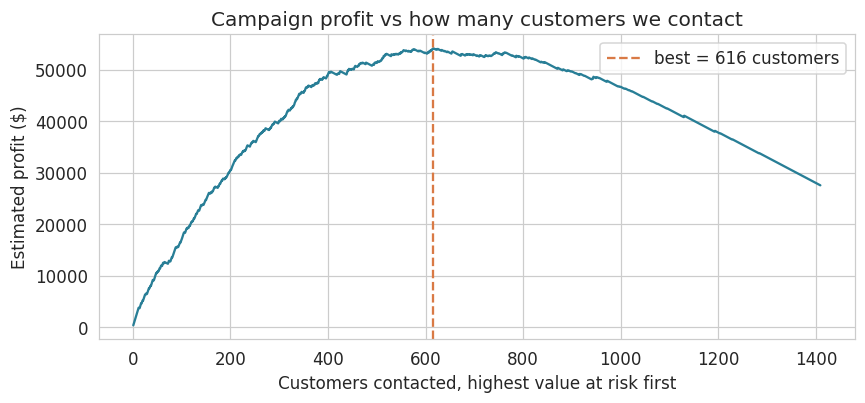

,tenure,Contract,MonthlyCharges,churn_probability,value_at_risk
0,7,Month-to-month,101.95,0.91,1114.16
1,3,Month-to-month,100.95,0.91,1099.15
2,3,Month-to-month,105.90,0.86,1092.20
3,7,Month-to-month,99.25,0.91,1086.10
4,6,Month-to-month,105.30,0.85,1076.52


In [37]:
plt.figure(figsize=(8, 3.8))
plt.plot(np.arange(1, len(ranked) + 1), ranked['profit'], color='#287E96')
plt.axvline(best_n, linestyle='--', color='#D97A45', label=f'best = {best_n} customers')
plt.xlabel('Customers contacted, highest value at risk first')
plt.ylabel('Estimated profit ($)')
plt.title('Campaign profit vs how many customers we contact')
plt.legend()
plt.tight_layout()
plt.show()

# top 5 customers on the list
ranked[['tenure', 'Contract', 'MonthlyCharges', 'churn_probability', 'value_at_risk']].head().round(2)

Profit goes up at first because the top of the list is mostly high value churners, then it flattens and drops once we're spending on people who were going to stay.

With these assumptions the best point is contacting the top 561 of 1,409 test customers. That gets 278 of the 374 churners and around \$54,000 in estimated profit. The top of the list is mostly new month-to-month customers paying over \$100 a month.

So the company shouldn't contact everyone the model flags. it should go down the ranked list and stop where it stops paying off. If the offer cost or success rate changes, so does that stopping point.

### Recommendations

1. Focus on the first year, since that's when most people leave. A check-in call in the first few months could help
2. Offer month-to-month customers a small discount to move to a one-year contract, but test it on a small group first
3. Give people a small reason to switch to auto-pay, since electronic check users churn the most
4. Look into why fiber optic customers leave, whether it's price or service quality
5. Try offering tech support and online security as a free trial to new customers and see if churn goes down
6. Use the model to rank customers by value at risk, not just to flag them

### Is it ready to deploy?

We'd say it's ready for a pilot but not a full rollout. It catches most churners but a lot of the flagged customers would have stayed anyway. it's trained on one snapshot so it would need regular retraining, and the senior citizen issue needs watching. The best next step is an A/B test, using the model on one group and not on another, to see if churn actually goes down.

## 14. Saving the model

We save the model together with the cutoff and the list of columns it expects. the `prepare_features` function from section 5 needs to be run on new data before using the model.

In [38]:
bundle = {
    'model': final_model,
    'model_name': selected_name,
    'cutoff': best_cutoff,
    'feature_columns': feature_columns,
    'versions': {
        'python': sys.version.split()[0],
        'scikit_learn': sklearn.__version__,
        'pandas': pd.__version__,
    },
}

model_path = Path('churn_model.joblib')
joblib.dump(bundle, model_path)

['churn_model.joblib']

In [39]:
# download the model file when running in colab
try:
    from google.colab import files
    files.download(str(model_path))
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Testing the saved model on new customers

Two made-up customers, one high risk and one loyal.

In [40]:
loaded = joblib.load(model_path)

new_customers = pd.DataFrame([
    {   # new customer, month-to-month, fiber optic, electronic check
        'customerID': 'NEW-001', 'gender': 'Female', 'SeniorCitizen': 'No', 'Partner': 'No',
        'Dependents': 'No', 'tenure': 3, 'PhoneService': 'Yes', 'MultipleLines': 'No',
        'InternetService': 'Fiber optic', 'OnlineSecurity': 'No', 'OnlineBackup': 'No',
        'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'Yes',
        'StreamingMovies': 'Yes', 'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes',
        'PaymentMethod': 'Electronic check', 'MonthlyCharges': 95.0, 'TotalCharges': 285.0,
    },
    {   # 5 years in, two-year contract, auto-pay by card
        'customerID': 'NEW-002', 'gender': 'Male', 'SeniorCitizen': 'No', 'Partner': 'Yes',
        'Dependents': 'Yes', 'tenure': 60, 'PhoneService': 'Yes', 'MultipleLines': 'Yes',
        'InternetService': 'DSL', 'OnlineSecurity': 'Yes', 'OnlineBackup': 'Yes',
        'DeviceProtection': 'Yes', 'TechSupport': 'Yes', 'StreamingTV': 'No',
        'StreamingMovies': 'No', 'Contract': 'Two year', 'PaperlessBilling': 'No',
        'PaymentMethod': 'Credit card (automatic)', 'MonthlyCharges': 70.0, 'TotalCharges': 4200.0,
    },
])

# same feature steps as before, then predict
new_X = prepare_features(new_customers)[loaded['feature_columns']]
new_prob = loaded['model'].predict_proba(new_X)[:, 1]

results = new_customers[['customerID', 'tenure', 'Contract', 'PaymentMethod']].copy()
results['churn_probability'] = new_prob.round(3)
results['prediction'] = np.where(new_prob >= loaded['cutoff'], 'Likely to churn', 'Likely to stay')
results

,customerID,tenure,Contract,PaymentMethod,churn_probability,prediction
0,NEW-001,3,Month-to-month,Electronic check,0.881,Likely to churn
1,NEW-002,60,Two year,Credit card (automatic),0.051,Likely to stay


In [41]:
# check the loaded model gives the same predictions as before saving
reloaded_prob = loaded['model'].predict_proba(X_test[loaded['feature_columns']])[:, 1]
assert np.allclose(test_prob, reloaded_prob)
print('saved model matches')

saved model matches


## 15. Summary

We cleaned the data by fixing `TotalCharges` and simplifying the service columns. There were no duplicates or outliers. Churn is highest among new month-to-month customers with fiber optic, paying by electronic check and without tech support or online security.

We added three features and compared a baseline, logistic regression, a decision tree and a random forest using a 60/20/20 split. Balancing the classes raised recall from 52% to 79%. The final model is a random forest with a 0.55 cutoff. On the test set it has an F1 of 0.63 and catches 72% of churners.

Contract, internet service and tenure matter most, but these are associations and not proven causes. The model treats men and women about the same but wrongly flags seniors about twice as often. For the business side, ranking customers by value at risk and stopping where offers stop paying off works better than contacting everyone. The model is ready for a pilot, not a full rollout.

**Data source:** IBM Telco Customer Churn dataset on Kaggle, https://www.kaggle.com/datasets/blastchar/telco-customer-churn, file `WA_Fn-UseC_-Telco-Customer-Churn.csv`, 7,043 rows and 21 columns.